In [233]:
import yfinance as yf
import pandas as pd
import scipy.stats as stats 
import matplotlib.pyplot as plt
import numpy as np 

In [52]:
yf.__version__

'1.3.0'

In [126]:
pd.options.display.float_format = '{:.2f}'.format

In [62]:
start_date = "2025 - 06 - 01"
end_date   = "2026 - 05 - 01"
ticker = "MSFT"

In [64]:
df = yf.download( tickers = "ticker" , start = "start_date" , end = "end_date" ,interval = "1d", multi_level_index = False )  

$TICKER: possibly delisted; no timezone found
[*********************100%***********************]  1 of 1 completed

1 Failed download:
['TICKER']: possibly delisted; no timezone found


In [66]:
yf.__version__

'1.3.0'

In [189]:
df = yf.download(tickers = "PENDLE-USD" , start = "2023-06-01" , end ="2026-06-01" , multi_level_index = False)  

[*********************100%***********************]  1 of 1 completed


In [190]:
df

,Close,High,Low,Open,Volume
Date,,,,,
2023-06-01,0.36,0.38,0.35,0.38,353298
2023-06-02,0.41,0.41,0.36,0.36,328764
2023-06-03,0.41,0.42,0.41,0.41,202511
2023-06-04,0.44,0.46,0.41,0.41,351898
2023-06-05,0.42,0.44,0.41,0.44,481267
...,...,...,...,...,...
2026-05-27,1.58,1.81,1.57,1.79,65296527
2026-05-28,1.46,1.58,1.45,1.58,58482485
2026-05-29,1.38,1.47,1.35,1.46,67304313


In [191]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1096 entries, 2023-06-01 to 2026-05-31
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   1096 non-null   float64
 1   High    1096 non-null   float64
 2   Low     1096 non-null   float64
 3   Open    1096 non-null   float64
 4   Volume  1096 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 51.4 KB


In [192]:
Close = df.Close.copy( )

In [193]:
Close

Date
2023-06-01   0.36
2023-06-02   0.41
2023-06-03   0.41
2023-06-04   0.44
2023-06-05   0.42
             ... 
2026-05-27   1.58
2026-05-28   1.46
2026-05-29   1.38
2026-05-30   1.33
2026-05-31   1.36
Name: Close, Length: 1096, dtype: float64

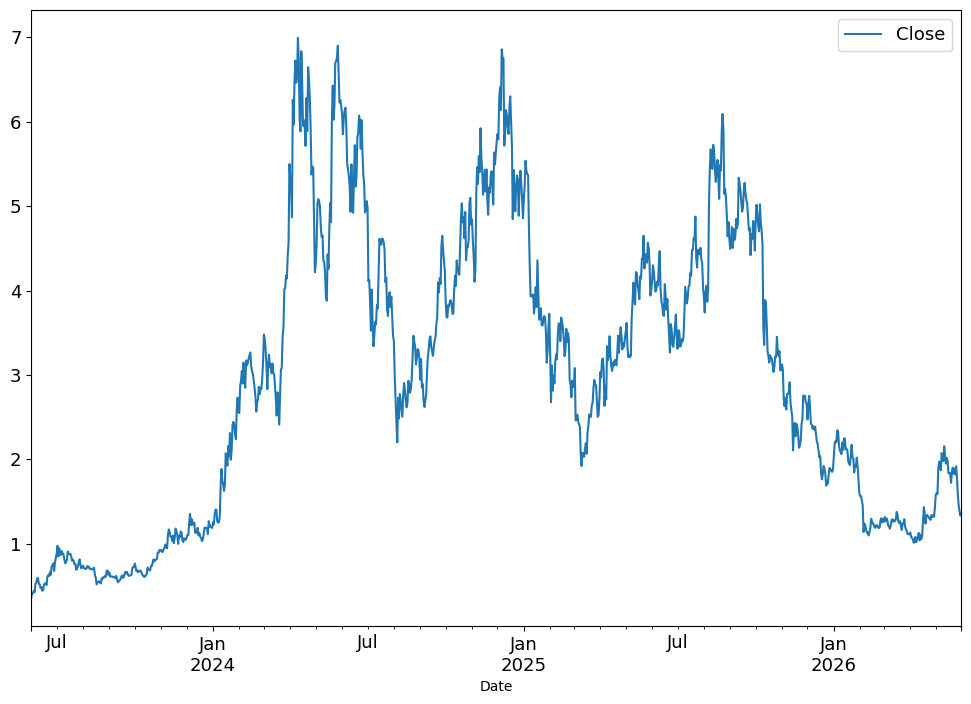

In [194]:
Close.dropna().plot(figsize = (12,8) , fontsize = 13 )
plt.legend(fontsize = 13) 
plt.show( ) 

In [195]:
pendle = Close.dropna().to_frame( ).copy() 

In [196]:
pendle

,Close
Date,
2023-06-01,0.36
2023-06-02,0.41
2023-06-03,0.41
2023-06-04,0.44
2023-06-05,0.42
...,...
2026-05-27,1.58
2026-05-28,1.46
2026-05-29,1.38


In [201]:
pendle["Close_lag1"]=pendle.Close.shift(1)   

In [202]:
pendle

,Close,Close_lag1,returns
Date,,,
2023-06-01,0.36,NaN,NaN
2023-06-02,0.41,0.36,0.14
2023-06-03,0.41,0.41,0.01
2023-06-04,0.44,0.41,0.06
2023-06-05,0.42,0.44,-0.03
...,...,...,...
2026-05-27,1.58,1.79,-0.12
2026-05-28,1.46,1.58,-0.08
2026-05-29,1.38,1.46,-0.05


In [199]:
pendle.drop( columns = ["pendle_lag1"] , axis = 1 ,inplace=True)   

KeyError: "['pendle_lag1'] not found in axis"

In [206]:
pendle

,Close,Close_lag1,returns
Date,,,
2023-06-01,0.36,NaN,NaN
2023-06-02,0.41,0.36,0.14
2023-06-03,0.41,0.41,0.01
2023-06-04,0.44,0.41,0.06
2023-06-05,0.42,0.44,-0.03
...,...,...,...
2026-05-27,1.58,1.79,-0.12
2026-05-28,1.46,1.58,-0.08
2026-05-29,1.38,1.46,-0.05


In [207]:
pendle["norm"]= pendle.Close.iloc[0]/(pendle.Close)*(100) 

In [208]:
pendle

,Close,Close_lag1,returns,norm
Date,,,,
2023-06-01,0.36,NaN,NaN,100.00
2023-06-02,0.41,0.36,0.14,87.55
2023-06-03,0.41,0.41,0.01,86.65
2023-06-04,0.44,0.41,0.06,81.38
2023-06-05,0.42,0.44,-0.03,84.32
...,...,...,...,...
2026-05-27,1.58,1.79,-0.12,22.68
2026-05-28,1.46,1.58,-0.08,24.57
2026-05-29,1.38,1.46,-0.05,25.90


In [209]:
pendle["returns"] = pendle.Close.div(pendle.Close_lag1) - 1

In [210]:
pendle

,Close,Close_lag1,returns,norm
Date,,,,
2023-06-01,0.36,NaN,NaN,100.00
2023-06-02,0.41,0.36,0.14,87.55
2023-06-03,0.41,0.41,0.01,86.65
2023-06-04,0.44,0.41,0.06,81.38
2023-06-05,0.42,0.44,-0.03,84.32
...,...,...,...,...
2026-05-27,1.58,1.79,-0.12,22.68
2026-05-28,1.46,1.58,-0.08,24.57
2026-05-29,1.38,1.46,-0.05,25.90


In [211]:
mu = pendle.returns.mean() 
mu

0.003073682776480188

In [212]:
std = pendle.returns.std() 
std

0.061456845644275296

In [213]:
pendle.describe() 

,Close,Close_lag1,returns,norm
count,1096.00,1095.00,1095.00,1096.00
mean,2.97,2.98,0.00,19.73
std,1.69,1.69,0.06,16.57
min,0.36,0.36,-0.22,5.12
25%,1.27,1.27,-0.03,8.40
50%,2.96,2.97,-0.00,12.07
75%,4.26,4.26,0.04,28.10
max,6.99,6.99,0.29,100.00


In [214]:
pendle.Close.div(pendle.Close.iloc[0])  # investment multiple 

Date
2023-06-01   1.00
2023-06-02   1.14
2023-06-03   1.15
2023-06-04   1.23
2023-06-05   1.19
             ... 
2026-05-27   4.41
2026-05-28   4.07
2026-05-29   3.86
2026-05-30   3.72
2026-05-31   3.81
Name: Close, Length: 1096, dtype: float64

In [215]:
pendle["log_rets"] = np.log(pendle.Close.div(pendle.Close.shift())) 

In [216]:
pendle

,Close,Close_lag1,returns,norm,log_rets
Date,,,,,
2023-06-01,0.36,NaN,NaN,100.00,NaN
2023-06-02,0.41,0.36,0.14,87.55,0.13
2023-06-03,0.41,0.41,0.01,86.65,0.01
2023-06-04,0.44,0.41,0.06,81.38,0.06
2023-06-05,0.42,0.44,-0.03,84.32,-0.04
...,...,...,...,...,...
2026-05-27,1.58,1.79,-0.12,22.68,-0.13
2026-05-28,1.46,1.58,-0.08,24.57,-0.08
2026-05-29,1.38,1.46,-0.05,25.90,-0.05


In [217]:
log_mu = pendle.log_rets.mean( ) 
log_mu

0.001222159923163751

In [218]:
log_std = pendle.log_rets.std( ) 
log_std

0.06062818409437547

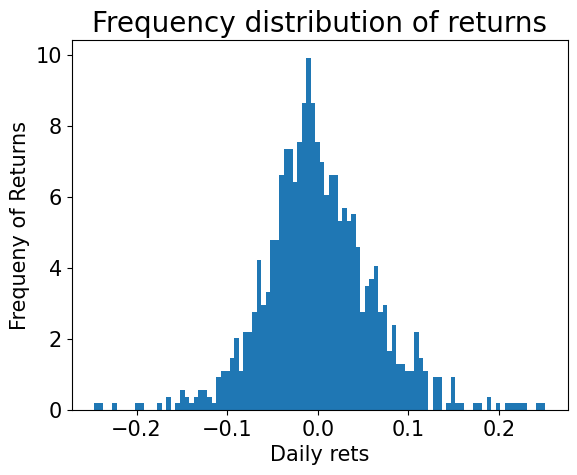

In [228]:
pendle.log_rets.plot(kind = "hist" , bins = 100 , fontsize = 15 , density = True ) 
plt.title("Frequency distribution of returns", fontsize = 20 )
plt.xlabel("Daily rets", fontsize = 15 )
plt.ylabel( "Frequeny of Returns",fontsize = 15 ) 
plt.show() 

In [224]:
from scipy.stats import skew

In [225]:
stats.skew(pendle.log_rets.dropna())     

C:\Users\Nick Frantzeskakis\AppData\Local\Temp\ipykernel_5476\2715025320.py:1: DeprecationWarning: Please import `skew` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  stats.skew(pendle.log_rets.dropna())


0.2609194765984044

In [226]:
from scipy.stats import kurtosis 

In [227]:
stats.kurtosis(pendle.log_rets.dropna() ,fisher=True)  

C:\Users\Nick Frantzeskakis\AppData\Local\Temp\ipykernel_5476\3455970770.py:1: DeprecationWarning: Please import `kurtosis` from the `scipy.stats` namespace; the `scipy.stats.stats` namespace is deprecated and will be removed in SciPy 2.0.0.
  stats.kurtosis(pendle.log_rets.dropna() ,fisher=True)


1.6382914154759796

In [243]:
x = np.linspace(pendle.log_rets.min() , pendle.log_rets.max() , 1000) 


In [244]:
y = stats.norm.pdf( x , loc = log_mu , scale = log_std ) 


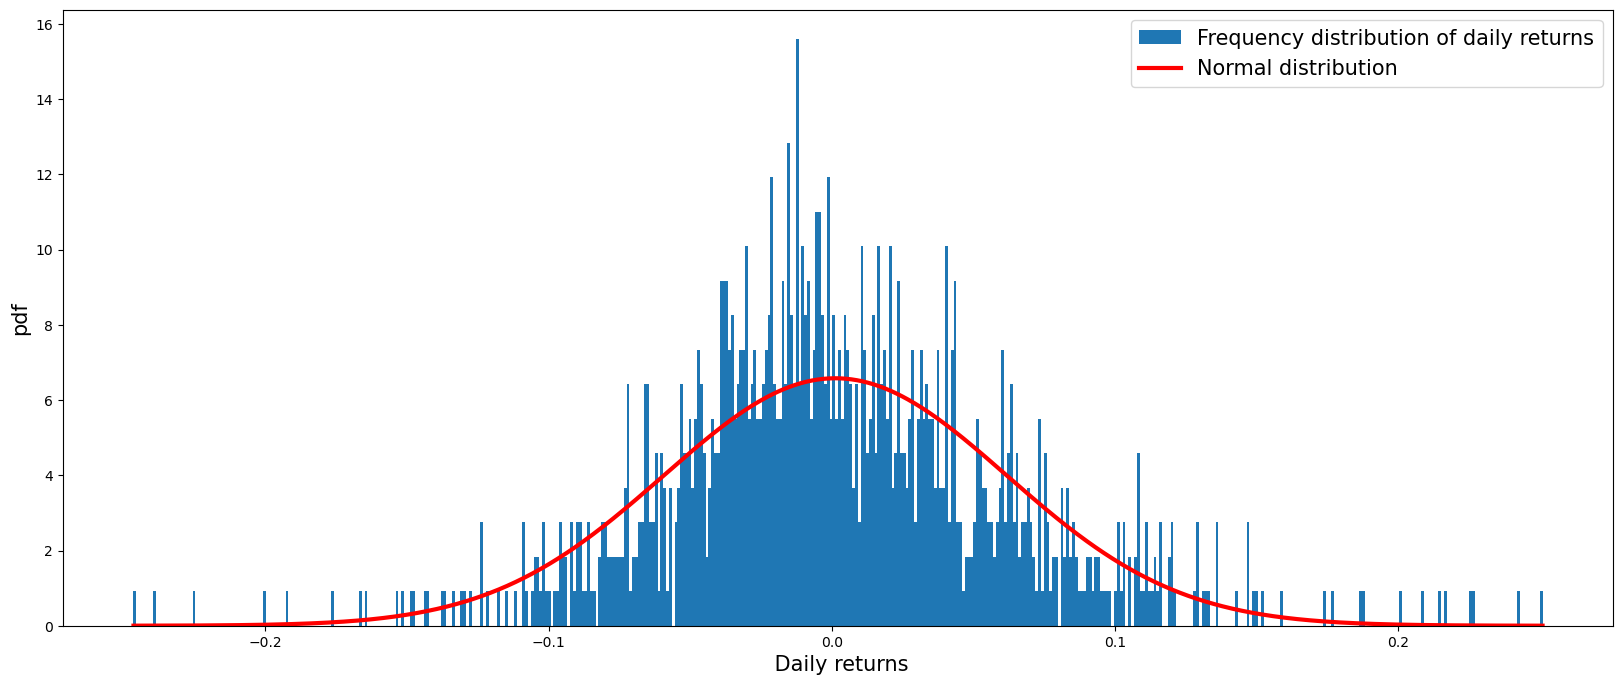

In [236]:
plt.figure(figsize = (20,8)) 
plt.hist(pendle.log_rets , bins = 500 , density = True , label = "Frequency distribution of daily returns")
plt.plot( x , y , linewidth = 3 , color = "red"   , label = "Normal distribution")
plt.xlabel(" Daily returns" , fontsize = 15) 
plt.ylabel( "pdf" , fontsize = 15 )
plt.legend(fontsize = 15)
plt.show( ) 

In [238]:
z_stat , p_value = stats.normaltest(pendle.log_rets.dropna())  

In [239]:
z_stat # high values -- reject Ho ( Ho : Pendle returns follow a normal distibution ) 

55.20960836908128

In [240]:
p_value # small values -- (close to zero) Pendle returns 

1.0265636181910124e-12